# 模块 6：视觉 PID 纯算法示例

本 notebook 直接复用 `pid_controller.py`，展示中心目标、方向符号、远近目标、多目标选择和 0.2 s 超时零输出。不导入 ROS 消息。

In [2]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
while root != root.parent and not (root / 'code' / 'pid_controller.py').is_file():
    root = root.parent
assert (root / 'code' / 'pid_controller.py').is_file(), '未找到项目根目录'
sys.path.insert(0, str(root / 'code'))

from datatypes import VisualTrack
from pid_controller import PIDController, command_from_track, on_timer, select_track

def controllers():
    return (PIDController(0.01, 0.0, 0.0, 1.0),
            PIDController(0.01, 0.0, 0.0, 1.0),
            PIDController(1.0, 0.0, 0.0, 2.0))

def command(track):
    return command_from_track(track, *controllers(), dt=0.02)

## 1. 中心目标与方向符号

右侧/下方目标产生负 `yaw_rate`/负 `velocity.z`，左侧/上方则相反。

In [3]:
cases = [
    ('center', VisualTrack(1, (270.0, 190.0, 100.0, 100.0), 0.10)),
    ('right/down', VisualTrack(2, (430.0, 310.0, 100.0, 100.0), 0.10)),
    ('left/up', VisualTrack(3, (110.0, 70.0, 100.0, 100.0), 0.10)),
]
commands = {}
for name, target in cases:
    commands[name] = command(target)
    print('%-10s velocity=%s yaw_rate=%+.3f' % (name, commands[name].velocity, commands[name].yaw_rate))
assert commands['center'].velocity == (0.0, 0.0, 0.0)
assert commands['center'].yaw_rate == 0.0
assert commands['right/down'].yaw_rate < 0 and commands['right/down'].velocity_z < 0
assert commands['left/up'].yaw_rate > 0 and commands['left/up'].velocity_z > 0

center     velocity=(0.0, 0.0, 0.0) yaw_rate=+0.000
right/down velocity=(0.0, 0.0, -1.0) yaw_rate=-1.000
left/up    velocity=(0.0, 0.0, 1.0) yaw_rate=+1.000


## 2. 远近目标的深度速度

直接面积误差策略为 `desired_area - max(area_ratio, min_area)`：远目标前进，达到期望面积时为零，进入末端阈值时使用末端速度。

In [4]:
for label, area in [('far', 0.01), ('desired', 0.10), ('near', 0.40)]:
    out = command(VisualTrack(10, (270.0, 190.0, 100.0, 100.0), area))
    print('%-8s area=%.2f velocity.x=%+.3f' % (label, area, out.velocity_x))
    if label == 'far':
        assert out.velocity_x > 0
    elif label == 'desired':
        assert out.velocity_x == 0
    else:
        assert out.velocity_x == 0

far      area=0.01 velocity.x=+0.090
desired  area=0.10 velocity.x=+0.000
near     area=0.40 velocity.x=+0.000


## 3. 多目标选择、短时保持与超时停止

选择面积最大者，同面积取最小 ID。空数组短时保持上次指令，超过 0.2 s 输出零速度。

In [5]:
targets = [
    VisualTrack(7, (270.0, 190.0, 100.0, 100.0), 0.03),
    VisualTrack(4, (270.0, 190.0, 100.0, 100.0), 0.08),
    VisualTrack(2, (270.0, 190.0, 100.0, 100.0), 0.08),
]
selected = select_track(targets)
fresh = on_timer(targets, 0.0, None, controllers=controllers())
held = on_timer([], 0.10, fresh, controllers=controllers())
stopped = on_timer([], 0.21, fresh, controllers=controllers())
print('selected id:', selected.id)
print('fresh      :', fresh)
print('held       :', held)
print('stopped    :', stopped)
assert selected.id == 2 and held == fresh
assert stopped.velocity == (0.0, 0.0, 0.0) and stopped.yaw_rate == 0.0
assert stopped.coordinate_frame == 9 and stopped.type_mask == 1479

selected id: 2
fresh      : PositionCommand(coordinate_frame=9, type_mask=1479, position=(0.0, 0.0, 0.0), velocity=(0.020000000000000004, 0.0, 0.0), yaw=0.0, yaw_rate=0.0)
held       : PositionCommand(coordinate_frame=9, type_mask=1479, position=(0.0, 0.0, 0.0), velocity=(0.020000000000000004, 0.0, 0.0), yaw=0.0, yaw_rate=0.0)
stopped    : PositionCommand(coordinate_frame=9, type_mask=1479, position=(0.0, 0.0, 0.0), velocity=(0.0, 0.0, 0.0), yaw=0.0, yaw_rate=0.0)


## 4. 效果图：方向符号与深度速度曲线

前几节用定值断言验证逻辑；下面把同一套 `pid_controller.py` 的结果画成曲线，便于直观检查算法效果（只调用实现，不复制逻辑）。

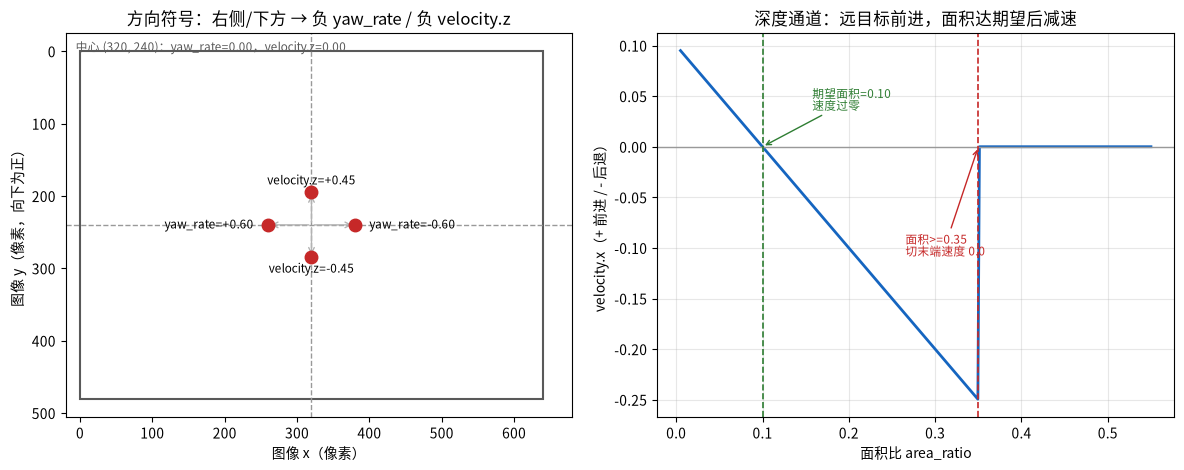

In [4]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
while root != root.parent and not (root / 'code' / 'pid_controller.py').is_file():
    root = root.parent
assert (root / 'code' / 'pid_controller.py').is_file(), '未找到项目根目录'
if str(root / 'code') not in sys.path:
    sys.path.insert(0, str(root / 'code'))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

import config as cfg
from datatypes import VisualTrack
from pid_controller import PIDController, command_from_track, on_timer

plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False


def controllers():
    return (PIDController(cfg.PID_YAW_KP, cfg.PID_YAW_KI, cfg.PID_YAW_KD, cfg.PID_YAW_MAX_OUT),
            PIDController(cfg.PID_VERTICAL_KP, cfg.PID_VERTICAL_KI, cfg.PID_VERTICAL_KD, cfg.PID_VERTICAL_MAX_OUT),
            PIDController(cfg.PID_DEPTH_KP, cfg.PID_DEPTH_KI, cfg.PID_DEPTH_KD, cfg.PID_DEPTH_MAX_OUT))


def command(area=0.10, cx=320.0, cy=240.0, dt=0.02):
    track = VisualTrack(1, (cx - 50.0, cy - 50.0, 100.0, 100.0), area)
    return command_from_track(track, *controllers(), dt=dt)


fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.8))

# --- 左：图像平面上的方向符号 ---
ax = axes[0]
ax.add_patch(plt.Rectangle((0.0, 0.0), cfg.PID_IMAGE_WIDTH, cfg.PID_IMAGE_HEIGHT,
                           fill=False, edgecolor='0.35', lw=1.5))
center_x, center_y = cfg.PID_IMAGE_WIDTH / 2.0, cfg.PID_IMAGE_HEIGHT / 2.0
ax.axvline(center_x, color='0.6', ls='--', lw=1)
ax.axhline(center_y, color='0.6', ls='--', lw=1)
samples = [('右', 380.0, 240.0, 20.0, 0.0, 'left'), ('左', 260.0, 240.0, -20.0, 0.0, 'right'),
           ('上', 320.0, 195.0, 0.0, -16.0, 'center'), ('下', 320.0, 285.0, 0.0, 16.0, 'center')]
for name, cx, cy, dx, dy, align in samples:
    out = command(cx=cx, cy=cy)
    ax.annotate('', xy=(cx, cy), xytext=(center_x, center_y),
                arrowprops=dict(arrowstyle='->', color='0.7', lw=1))
    ax.plot(cx, cy, marker='o', ms=9, color='#c62828', zorder=3)
    text = 'yaw_rate=%+.2f' % out.yaw_rate if name in ('右', '左') else 'velocity.z=%+.2f' % out.velocity_z
    ax.text(cx + dx, cy + dy, text, ha=align, va='center', fontsize=8.5, zorder=4)
ax.text(0.02, 0.04, '中心 (320, 240)：yaw_rate=0.00，velocity.z=0.00', transform=ax.transAxes,
        ha='left', va='bottom', fontsize=8.5, color='0.35')
ax.set_xlim(-20.0, cfg.PID_IMAGE_WIDTH + 40.0)
ax.set_ylim(cfg.PID_IMAGE_HEIGHT + 25.0, -25.0)
ax.set_aspect('equal')
ax.set_xlabel('图像 x（像素）')
ax.set_ylabel('图像 y（像素，向下为正）')
ax.set_title('方向符号：右侧/下方 → 负 yaw_rate / 负 velocity.z')

# --- 右：面积 - 前进速度 ---
ax = axes[1]
area_axis = np.linspace(0.005, 0.55, 300)
velocity_axis = [command(area=float(a)).velocity_x for a in area_axis]
ax.plot(area_axis, velocity_axis, color='#1565c0', lw=2, label='velocity.x')
ax.axhline(0.0, color='0.6', lw=1)
ax.axvline(cfg.PID_DESIRED_AREA, color='#2e7d32', ls='--', lw=1.2)
ax.axvline(cfg.PID_IMPACT_AREA_THRESHOLD, color='#c62828', ls='--', lw=1.2)
ax.annotate('期望面积=%.2f\n速度过零' % cfg.PID_DESIRED_AREA, xy=(cfg.PID_DESIRED_AREA, 0.0),
            xycoords='data', xytext=(0.30, 0.80), textcoords='axes fraction', fontsize=8.5,
            color='#2e7d32', arrowprops=dict(arrowstyle='->', color='#2e7d32', lw=1))
ax.annotate('面积>=%.2f\n切末端速度 %.1f' % (cfg.PID_IMPACT_AREA_THRESHOLD, cfg.PID_TERMINAL_FORWARD_SPEED),
            xy=(cfg.PID_IMPACT_AREA_THRESHOLD, 0.0), xycoords='data',
            xytext=(0.48, 0.42), textcoords='axes fraction', fontsize=8.5,
            color='#c62828', arrowprops=dict(arrowstyle='->', color='#c62828', lw=1))
ax.set_xlabel('面积比 area_ratio')
ax.set_ylabel('velocity.x（+ 前进 / - 后退）')
ax.set_title('深度通道：远目标前进，面积达期望后减速')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. 效果图：深度闭环收敛与 50 Hz 超时保护

左图用一阶面积模型展示「面积 → 前进速度 → 面积」的闭环收敛；右图展示 `on_timer` 在断流后的「短时重发 → 超时零输出」时序（保持窗口 `PID_HOLD_TIMEOUT=0.2s`）。

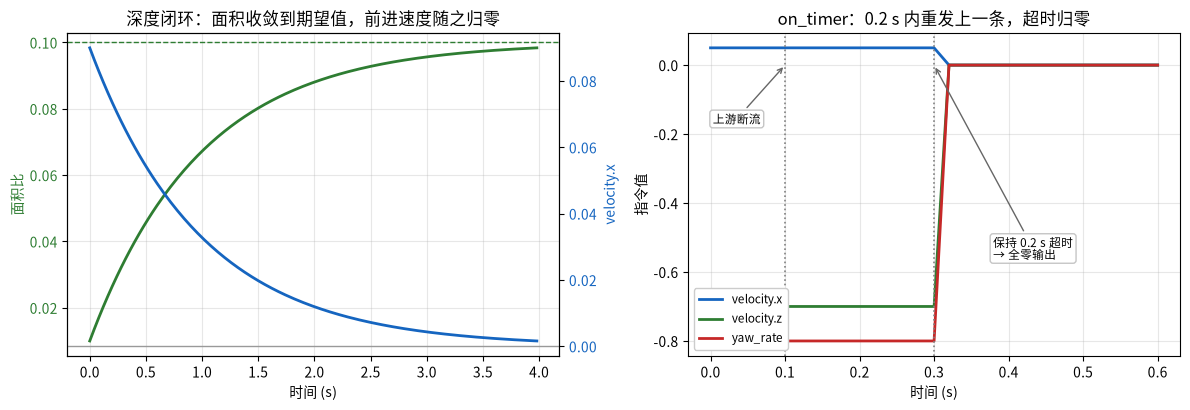

In [5]:
dt = 1.0 / cfg.PID_RATE_HZ

# --- 左：深度闭环（面积 -> 前进速度 -> 面积变化的一阶模型）---
area = 0.01
area_gain = 1.0
history = []
for step in range(int(4.0 / dt)):
    out = command_from_track(VisualTrack(1, (270.0, 190.0, 100.0, 100.0), area),
                             *controllers(), dt=dt)
    history.append((step * dt, area, out.velocity_x))
    area = area + area_gain * out.velocity_x * dt

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.2))

ax = axes[0]
time_axis = [item[0] for item in history]
area_curve = [item[1] for item in history]
velocity_curve = [item[2] for item in history]
ax.plot(time_axis, area_curve, color='#2e7d32', lw=2)
ax.axhline(cfg.PID_DESIRED_AREA, color='#2e7d32', ls='--', lw=1)
ax.set_xlabel('时间 (s)')
ax.set_ylabel('面积比', color='#2e7d32')
ax.tick_params(axis='y', labelcolor='#2e7d32')
ax.set_title('深度闭环：面积收敛到期望值，前进速度随之归零')
ax.grid(alpha=0.3)
ax2 = ax.twinx()
ax2.plot(time_axis, velocity_curve, color='#1565c0', lw=2)
ax2.axhline(0.0, color='0.6', lw=1)
ax2.set_ylabel('velocity.x', color='#1565c0')
ax2.tick_params(axis='y', labelcolor='#1565c0')

# --- 右：50 Hz on_timer 超时保护 ---
ax = axes[1]
ctrl = controllers()
target = VisualTrack(1, (350.0, 260.0, 100.0, 100.0), 0.05)
fresh = command_from_track(target, *ctrl, dt=dt)
last_input = 0.10
times = np.arange(0.0, 0.61, dt)
vx, vz, yaw = [], [], []
for t in times:
    if t <= last_input:
        out = on_timer([target], 0.0, None, controllers=ctrl, dt=dt)
    else:
        out = on_timer([], t - last_input, fresh, controllers=ctrl, dt=dt)
    vx.append(out.velocity_x)
    vz.append(out.velocity_z)
    yaw.append(out.yaw_rate)
ax.plot(times, vx, color='#1565c0', lw=2, label='velocity.x')
ax.plot(times, vz, color='#2e7d32', lw=2, label='velocity.z')
ax.plot(times, yaw, color='#c62828', lw=2, label='yaw_rate')
ax.axvline(last_input, color='0.5', ls=':', lw=1.2)
ax.axvline(last_input + cfg.PID_HOLD_TIMEOUT, color='0.5', ls=':', lw=1.2)
box = dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.75', alpha=0.9)
ax.annotate('上游断流', xy=(last_input, 0.0), xycoords='data', xytext=(0.05, 0.72),
            textcoords='axes fraction', fontsize=8.5, bbox=box,
            arrowprops=dict(arrowstyle='->', color='0.4', lw=1))
ax.annotate('保持 %.1f s 超时\n→ 全零输出' % cfg.PID_HOLD_TIMEOUT,
            xy=(last_input + cfg.PID_HOLD_TIMEOUT, 0.0), xycoords='data',
            xytext=(0.62, 0.30), textcoords='axes fraction', fontsize=8.5, bbox=box,
            arrowprops=dict(arrowstyle='->', color='0.4', lw=1))
ax.set_xlabel('时间 (s)')
ax.set_ylabel('指令值')
ax.set_title('on_timer：0.2 s 内重发上一条，超时归零')
ax.legend(fontsize=8.5, loc='lower left', framealpha=1.0)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()